In [32]:
import math as m
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.optimize import curve_fit
from dust_extinction.parameter_averages import CCM89, F99

In [33]:
dataUV = pd.read_csv("HD_104994_IUE_spectrum.a", sep="\s+", comment="#")
dataUVES = pd.read_csv("HD_104994_UVES_VLT_spectrum.a", sep="\s+", comment="#")
dataTheory = pd.read_csv("wne_14-13_sed.txt", sep="\s+", comment="#")

wlUV = dataUV.iloc[:, 0].values
wlUVES = dataUVES.iloc[:, 0].values
Fuv = dataUV.iloc[:, 1].values
Fuves = dataUVES.iloc[:, 1].values
wlTheory = 10 ** (dataTheory.iloc[:, 0].values)
Ftheory = 10 ** (dataTheory.iloc[:, 1].values)
nombres_cols = ["lambda_mu", "mag", "emag", "Flambda", "eFlambda", "Band", "System"]
datos = pd.read_csv(
    "HD_104994_photometry.txt", sep="\s+", skiprows=3, names=nombres_cols
)
wlBANDS = datos["lambda_mu"].values * 1e4
mag = datos["mag"].values
Flambda = datos["Flambda"].values
error_Flambda = datos["eFlambda"].values
error_mag = datos["emag"].values
bandas = datos["Band"].values

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\2596031361.py:1: SyntaxWarning: invalid escape sequence '\s'
  dataUV = pd.read_csv("HD_104994_IUE_spectrum.a", sep="\s+", comment="#")
C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\2596031361.py:2: SyntaxWarning: invalid escape sequence '\s'
  dataUVES = pd.read_csv("HD_104994_UVES_VLT_spectrum.a", sep="\s+", comment="#")
C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\2596031361.py:3: SyntaxWarning: invalid escape sequence '\s'
  dataTheory = pd.read_csv("wne_14-13_sed.txt", sep="\s+", comment="#")
C:\Users\luis0\AppData\Local\Temp\ip

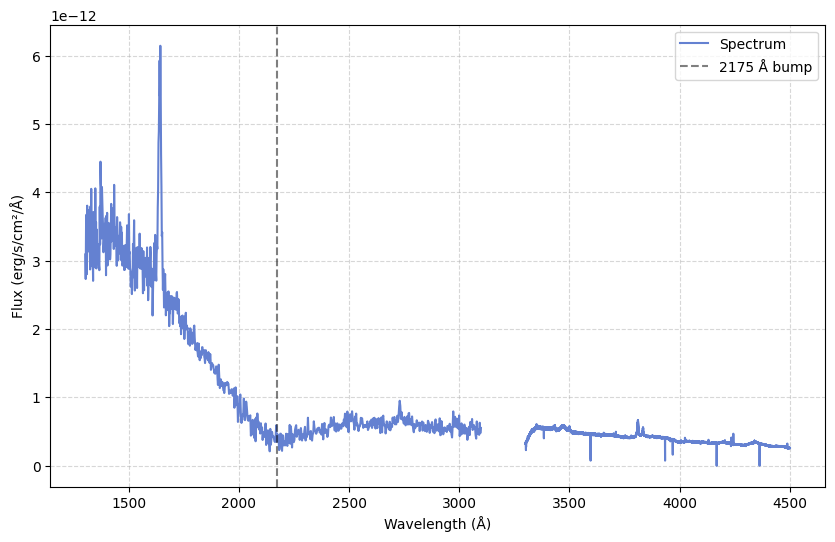

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(wlUV, Fuv, label="Spectrum", color="#6481d1", lw=1.5)
ax.plot(wlUVES, Fuves, color="#6481d1", lw=1.5)
ax.axvline(x=2175, color="k", linestyle="--", label="2175 Å bump", alpha=0.5)
ax.grid(alpha=0.5, linestyle="--")
ax.set_xlabel("Wavelength (Å)")
ax.set_ylabel("Flux (erg/s/cm²/Å)")
ax.legend()
plt.savefig(
    "HD104994Spectra.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

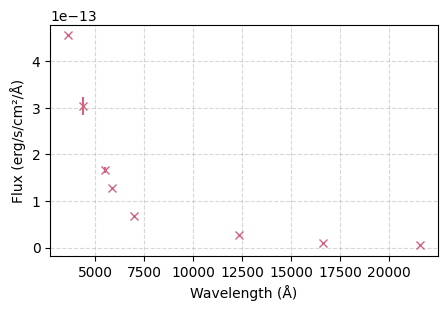

In [35]:
fig, ax1 = plt.subplots(figsize=(5, 3))
ax1.errorbar(wlBANDS, Flambda, yerr=error_Flambda, fmt="x", color="#d16481")
ax1.set_xlabel("Wavelength (Å)")
ax1.set_ylabel("Flux (erg/s/cm²/Å)")
ax1.grid(alpha=0.5, linestyle="--")

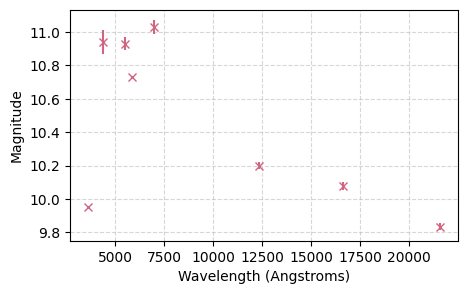

In [36]:
fig, ax2 = plt.subplots(figsize=(5, 3))
ax2.errorbar(wlBANDS, mag, yerr=error_mag, fmt="x", color="#d16481")
ax2.set_xlabel("Wavelength (Angstroms)")
ax2.set_ylabel("Magnitude")
ax2.grid(alpha=0.5, linestyle="--")

In [37]:
F_theoUV = np.interp(wlUV, wlTheory, Ftheory)
F_theoUVES = np.interp(wlUVES, wlTheory, Ftheory)
F_theo_interp = np.concatenate((F_theoUV, F_theoUVES)) * (10 / 2360) ** 2
F_exp_interp = np.concatenate((Fuv, Fuves))
wl_interp = np.concatenate((wlUV, wlUVES))
F_V_Theo = np.interp(5500, wlTheory, Ftheory) * (10 / 2360) ** 2
F_V_exp = 1.6645e-13

C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\1132082237.py:1: RuntimeWarning: divide by zero encountered in log10
  Ext_Curve = -2.5 * np.log10(F_exp_interp / F_theo_interp * (F_V_Theo / F_V_exp))


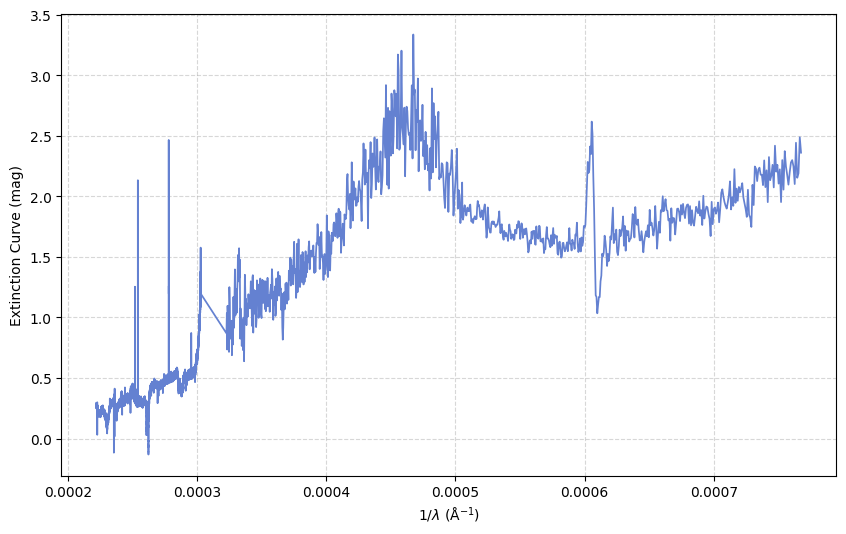

In [ ]:
Ext_Curve = -2.5 * np.log10(F_exp_interp / F_theo_interp * (F_V_Theo / F_V_exp))
Ext_Curve_Full = Ext_Curve
wl_interp_Full = wl_interp
fig, ax3 = plt.subplots(figsize=(10, 6))
ax3.plot(1 / wl_interp, Ext_Curve, color="#6481d1", lw=1.25)
ax3.set_xlabel(r"$1/\lambda$ (Å$^{-1}$)")
ax3.set_ylabel("Extinction Curve (mag)")
ax3.grid(alpha=0.5, linestyle="--")
a_v = 2.5 * np.log10(F_V_Theo / F_V_exp)
inv_wl = 1 / wl_interp
tabla_resultados = pd.DataFrame(
    {"1/lambda_invA": inv_wl, "Extinction_Curve_mag": Ext_Curve}
)
tabla_resultados.to_csv("Curva_Extincion_WR46.csv", index=False)

plt.savefig(
    "ExtinctionCurve_HD104994.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [ ]:
Ext_Curve = -2.5 * np.log10(F_exp_interp / F_theo_interp * (F_V_Theo / F_V_exp))
a_v = 2.5 * np.log10(F_V_Theo / F_V_exp)


x_micras_inv = inv_wl * 1e4


wl = 1 / inv_wl * 1e4
ext_curve = Ext_Curve

mascara_valida = np.ones(len(x_micras_inv), dtype=bool)

mascara_valida &= ~((x_micras_inv > 2.32) & (x_micras_inv < 2.38))  # Pico 1
mascara_valida &= ~((x_micras_inv > 2.52) & (x_micras_inv < 2.56))  # Pico 2
mascara_valida &= ~((x_micras_inv > 2.76) & (x_micras_inv < 2.80))  # Pico 3
mascara_valida &= ~((x_micras_inv > 3.00) & (x_micras_inv < 3.05))  # Pico 4
mascara_valida &= ~((x_micras_inv > 6.02) & (x_micras_inv < 6.08))

x_limpio = x_micras_inv[mascara_valida]
ext_curve_limpia = ext_curve[mascara_valida]
mascara_finita = np.isfinite(ext_curve_limpia) & np.isfinite(x_limpio)


x_limpio = x_limpio[mascara_finita]
ext_curve_limpia = ext_curve_limpia[mascara_finita]

C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\1139165366.py:1: RuntimeWarning: divide by zero encountered in log10
  Ext_Curve = -2.5 * np.log10(F_exp_interp / F_theo_interp * (F_V_Theo / F_V_exp))


R_V ajustado (CCM89) = 3.047 ± 0.007
R_V ajustado (F99)   = 2.997 ± 0.007


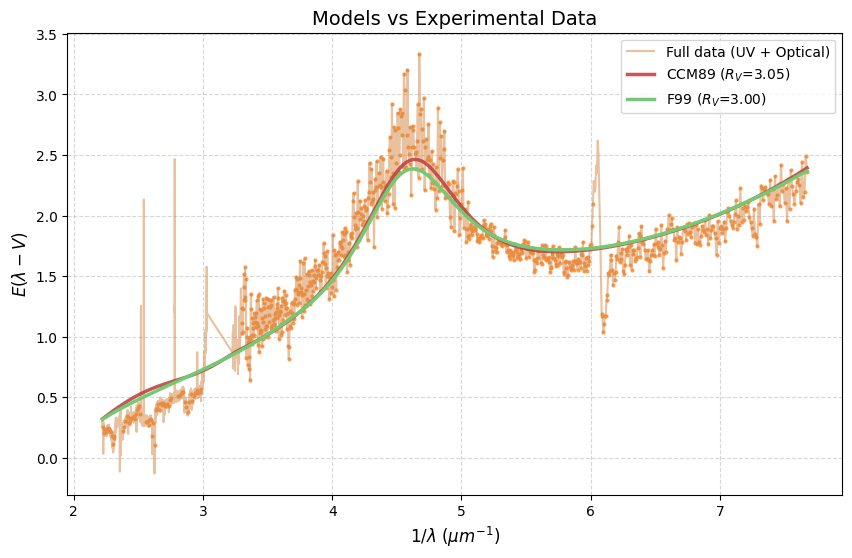

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os


def modelo_ccm89(x_data, r_v):
    ext = CCM89(Rv=r_v)
    return a_v * (ext(x_data) - 1.0)


def modelo_f99(x_data, r_v):
    ext = F99(Rv=r_v)
    return a_v * (ext(x_data) - 1.0)


umbral_corte = 3.3
mascara_optico = x_limpio < umbral_corte
mascara_uv = x_limpio >= umbral_corte

salto = 1000
x_optico_diezmado = x_limpio[mascara_optico][::salto]
y_optico_diezmado = ext_curve_limpia[mascara_optico][::salto]

x_uv = x_limpio[mascara_uv]
y_uv = ext_curve_limpia[mascara_uv]

x_para_ajuste = np.concatenate((x_optico_diezmado, x_uv))
y_para_ajuste = np.concatenate((y_optico_diezmado, y_uv))

popt_ccm, pcov_ccm = curve_fit(
    f=modelo_ccm89,
    xdata=x_para_ajuste,
    ydata=y_para_ajuste,
    p0=[3.6],
    bounds=(2.01, 5.99),
)
best_Rv_ccm = popt_ccm[0]
error_Rv_ccm = np.sqrt(np.diag(pcov_ccm))[0]

popt_f99, pcov_f99 = curve_fit(
    f=modelo_f99,
    xdata=x_para_ajuste,
    ydata=y_para_ajuste,
    p0=[3.6],
    bounds=(2.01, 5.99),
)
best_Rv_f99 = popt_f99[0]
error_Rv_f99 = np.sqrt(np.diag(pcov_f99))[0]

print(f"R_V ajustado (CCM89) = {best_Rv_ccm:.3f} ± {error_Rv_ccm:.3f}")
print(f"R_V ajustado (F99)   = {best_Rv_f99:.3f} ± {error_Rv_f99:.3f}")


plt.figure(figsize=(10, 6))

plt.plot(
    1 / wl_interp_Full * 1e4,
    Ext_Curve_Full,
    lw=1.5,
    color="#d48441",
    alpha=0.5,
    label="Full data (UV + Optical)",
)


plt.scatter(
    x_para_ajuste,
    y_para_ajuste,
    s=4,
    color="#fc9846",
    alpha=0.9,
)


x_continuo = np.linspace(np.min(x_limpio), np.max(x_limpio), 1000)


y_ajuste_ccm = modelo_ccm89(x_continuo, best_Rv_ccm)
plt.plot(
    x_continuo,
    y_ajuste_ccm,
    color="#be4444e4",
    linewidth=2.5,
    label=rf"CCM89 ($R_V$={best_Rv_ccm:.2f})",
)


y_ajuste_f99 = modelo_f99(x_continuo, best_Rv_f99)
plt.plot(
    x_continuo,
    y_ajuste_f99,
    color="#72ca72",
    linewidth=2.5,
    linestyle="-",
    label=rf"F99 ($R_V$={best_Rv_f99:.2f})",
)

plt.xlabel(r"$1/\lambda$ ($\mu m^{-1}$)", fontsize=12)
plt.ylabel(r"$E(\lambda - V)$", fontsize=12)
plt.title(f"Models vs Experimental Data", fontsize=14)
plt.grid(alpha=0.5, linestyle="--")
plt.legend()
plt.savefig(
    "ComparisonCCM89F99.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
plt.show()

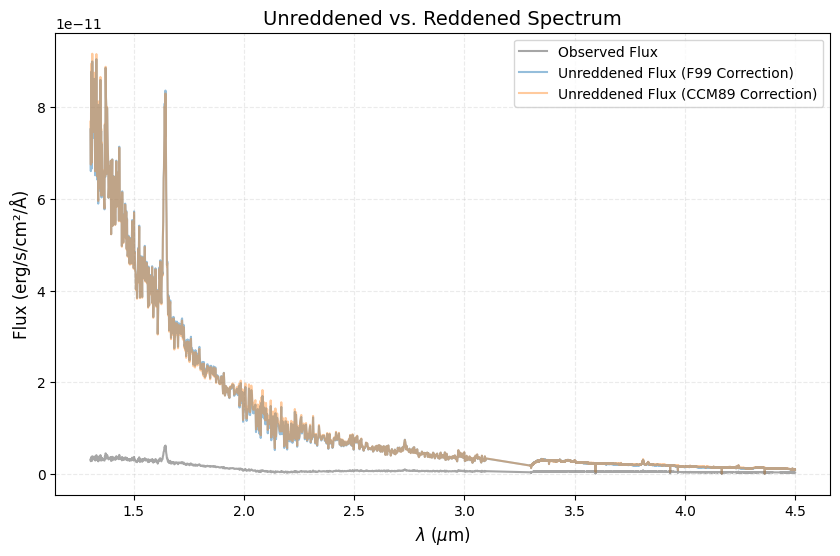

In [ ]:
ext_f99 = F99(Rv=best_Rv_f99)
ext_ccm89 = CCM89(Rv=best_Rv_ccm)

A_lambda = a_v * ext_f99(x_micras_inv)
A_lambda_ccm = a_v * ext_ccm89(x_micras_inv)

F_unred = F_exp_interp * 10 ** (0.4 * A_lambda)
F_unred_ccm = F_exp_interp * 10 ** (0.4 * A_lambda_ccm)

plt.figure(figsize=(10, 6))

plt.plot(
    wl * 1e-7,
    F_exp_interp,
    color="gray",
    alpha=0.7,
    label="Observed Flux",
)

plt.plot(
    wl * 1e-7,
    F_unred,
    color="#1f76b478",
    linewidth=1.5,
    label="Unreddened Flux (F99 Correction)",
)

plt.plot(
    wl * 1e-7,
    F_unred_ccm,
    color="#ff7e0e67",
    linewidth=1.5,
    label="Unreddened Flux (CCM89 Correction)",
)

plt.xlabel(r"$\lambda\; (\mu\text{m})$", fontsize=12)
plt.ylabel(r"Flux (erg/s/cm²/Å)", fontsize=12)
plt.title("Unreddened vs. Reddened Spectrum", fontsize=14)
plt.legend()


plt.savefig(
    fname="Espectro_Desenrojecido.png", dpi=300, bbox_inches="tight", transparent=True
)
plt.grid(alpha=0.25, linestyle="--")
plt.show()

In [ ]:
lambda_mu = []
mag = []
emag = []
Flambda = []
eFlambda = []
bandas = []
sistemas = []

with open("HD_104994_photometry.txt", "r") as archivo:
    lineas = archivo.readlines()

    for linea in lineas[3:]:
        if linea.strip():
            columnas = linea.split()

            lambda_mu.append(float(columnas[0]))
            mag.append(float(columnas[1]))
            emag.append(float(columnas[2]))
            Flambda.append(float(columnas[3]))
            eFlambda.append(float(columnas[4]))

            bandas.append(columnas[5])
            if len(columnas) > 6:
                sistemas.append(columnas[6])
            else:
                sistemas.append("")

lambda_mu = np.array(lambda_mu)
Flambda = np.array(Flambda)
mag = np.array(mag)
emag = np.array(emag)
eFlambda = np.array(eFlambda)

In [ ]:
ultimos_lambda_mu = lambda_mu[-3:]
ultimos_Flambda = Flambda[-3:]

Temperatura ajustada: 142990 ± 11618 K


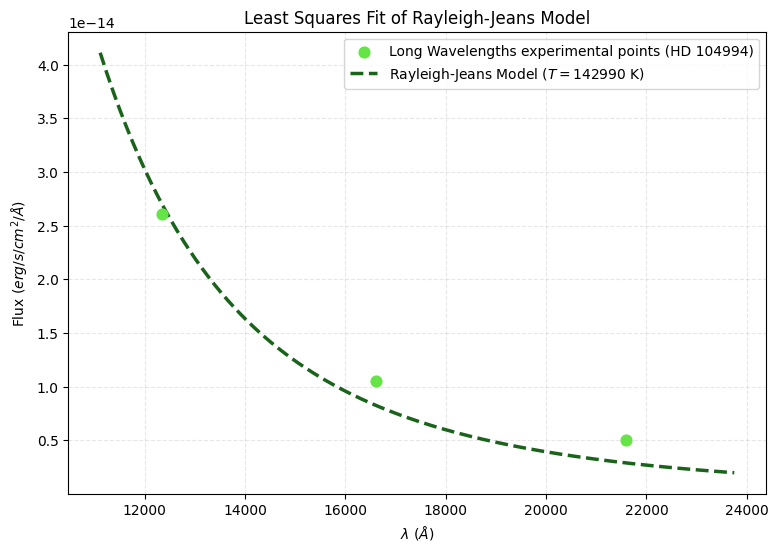

In [ ]:
def flujo_rayleigh_jeans(wl_angstroms, T):
    c = 2.99792458e10
    k = 1.380649e-16

    wl_cm = wl_angstroms * 1e-8
    B_lambda_rj = (2.0 * c * k * T) / (wl_cm**4)

    factor_dilucion = np.pi * (R_estrella / d_estrella) ** 2
    F_rj_cm = factor_dilucion * B_lambda_rj

    # Return flux in erg/s/cm^2/A
    return F_rj_cm * 1e-8


R_estrella = 1.36 * 6.957e10  # cm
d_estrella = 2360 * 3.086e18  # cm

wl_ajuste_angstroms = ultimos_lambda_mu * 10000.0

popt_rj, pcov_rj = curve_fit(
    f=flujo_rayleigh_jeans,
    xdata=wl_ajuste_angstroms,
    ydata=ultimos_Flambda,
    p0=[30000.0],
)

T_rj = popt_rj[0]
error_T = np.sqrt(np.diag(pcov_rj))[0]

print(f"Temperatura ajustada: {T_rj:.0f} ± {error_T:.0f} K")

plt.figure(figsize=(9, 6))

plt.scatter(
    wl_ajuste_angstroms,
    ultimos_Flambda,
    s=60,
    color="#65e445",
    label="Long Wavelengths experimental points (HD 104994)",
    zorder=5,
)

x_continuo = np.linspace(
    np.min(wl_ajuste_angstroms) * 0.9, np.max(wl_ajuste_angstroms) * 1.1, 200
)
y_ajuste = flujo_rayleigh_jeans(x_continuo, T_rj)

plt.plot(
    x_continuo,
    y_ajuste,
    color="#1a631a",
    linewidth=2.5,
    linestyle="--",
    label=rf"Rayleigh-Jeans Model ($T={T_rj:.0f}$ K)",
)

plt.xlabel(r"$\lambda$ ($\AA$)")
plt.ylabel(r"Flux ($erg/s/cm^2/\AA$)")
plt.title("Least Squares Fit of Rayleigh-Jeans Model")
plt.legend()
plt.grid(alpha=0.3, linestyle="--")
plt.savefig(
    "RayleighJeans_Fit.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
plt.show()

C:\Users\luis0\AppData\Local\Temp\ipykernel_41084\1635680050.py:24: RuntimeWarning: divide by zero encountered in log10
  ext_curve_planck = -2.5 * (np.log10(F_exp_interp / F_t_plank) +


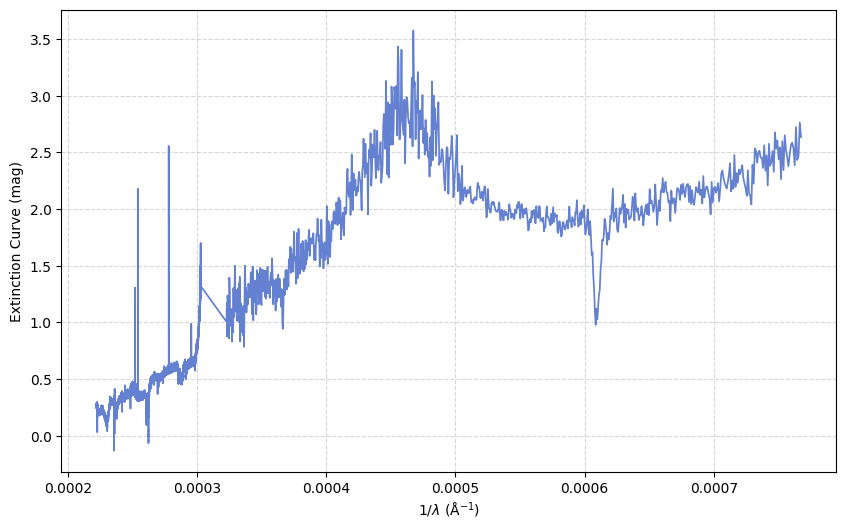

In [ ]:
def F_theo(lambda_ang, T):
    def B_lambda(T):
        h = 6.62607015e-27  # erg * s
        c = 2.99792458e10  # cm / s
        k = 1.380649e-16  # erg / K
        wl_cm = lambda_ang * 1e-8
        # Pre-factor: 2hc^2 / lambda^5
        termino_pre = (2.0 * h * c**2) / (wl_cm**5)

        exponente = (h * c) / (wl_cm * k * T)

        intensidad = termino_pre / (np.exp(exponente) - 1.0)
        return intensidad

    F_planck = np.pi * (R_estrella / d_estrella) ** 2 * B_lambda(T) * 1e-8
    return F_planck


F_t_plank = F_theo(wl_interp, T_rj)
F_v_planck = flujo_rayleigh_jeans(5500, T_rj)

ext_curve_planck = -2.5 * (
    np.log10(F_exp_interp / F_t_plank) + np.log10(F_v_planck / F_V_exp)
)
Ext_Curve_Full_Planck = ext_curve_planck
a_v_planck = 2.5 * np.log10(F_v_planck / F_V_exp)

fig, ax4 = plt.subplots(figsize=(10, 6))
ax4.plot(1 / wl_interp, ext_curve_planck, color="#6481d1", lw=1.25)
ax4.set_xlabel(r"$1/\lambda$ (Å$^{-1}$)")
ax4.set_ylabel("Extinction Curve (mag)")
ax4.grid(alpha=0.5, linestyle="--")

plt.savefig(
    "ExtinctionCurve_HD104994_Planck.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

R_V ajustado (CCM89) = 3.461 ± 0.006
R_V ajustado (F99)   = 3.388 ± 0.006


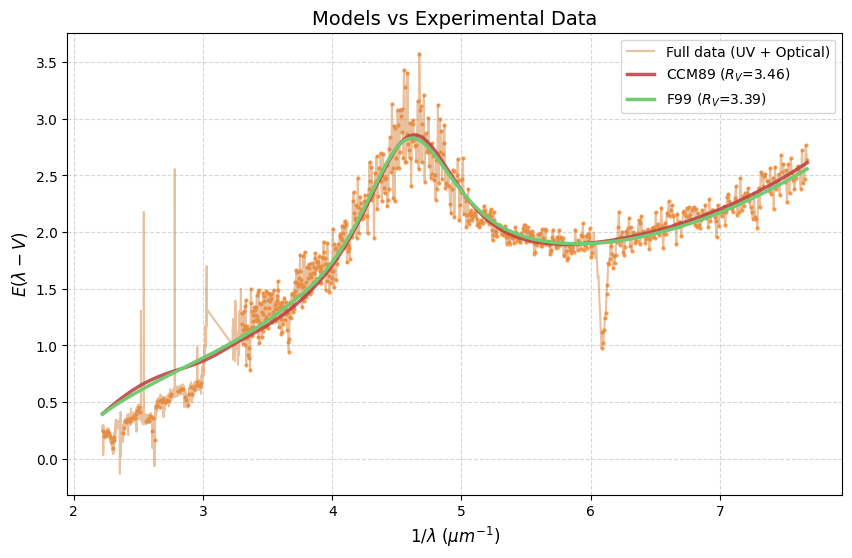

In [ ]:
def modelo_ccm89(x_data, r_v):
    ext = CCM89(Rv=r_v)
    return a_v_planck * (ext(x_data) - 1.0)


def modelo_f99(x_data, r_v):
    ext = F99(Rv=r_v)
    return a_v_planck * (ext(x_data) - 1.0)


eje_x_original = 10000.0 / wl_interp

x_limpio = eje_x_original[mascara_valida]
ext_curve_planck_limpia = ext_curve_planck[mascara_valida]

mascara_finita = np.isfinite(ext_curve_planck_limpia) & np.isfinite(x_limpio)

x_limpio = x_limpio[mascara_finita]
ext_curve_planck_limpia = ext_curve_planck_limpia[mascara_finita]

umbral_corte = 3.3
mascara_optico = x_limpio < umbral_corte
mascara_uv = x_limpio >= umbral_corte

salto = 1000
x_optico_diezmado = x_limpio[mascara_optico][::salto]
y_optico_diezmado = ext_curve_planck_limpia[mascara_optico][::salto]

x_uv = x_limpio[mascara_uv]
y_uv = ext_curve_planck_limpia[mascara_uv]

x_para_ajuste = np.concatenate((x_optico_diezmado, x_uv))
y_para_ajuste = np.concatenate((y_optico_diezmado, y_uv))

mascara_rango_valido = (x_para_ajuste >= 0.3) & (x_para_ajuste <= 10.0)
x_para_ajuste = x_para_ajuste[mascara_rango_valido]
y_para_ajuste = y_para_ajuste[mascara_rango_valido]

popt_ccm, pcov_ccm = curve_fit(
    f=modelo_ccm89,
    xdata=x_para_ajuste,
    ydata=y_para_ajuste,
    p0=[3.6],
    bounds=(2.01, 5.99),
)
best_Rv_ccm = popt_ccm[0]
error_Rv_ccm = np.sqrt(np.diag(pcov_ccm))[0]

popt_f99, pcov_f99 = curve_fit(
    f=modelo_f99,
    xdata=x_para_ajuste,
    ydata=y_para_ajuste,
    p0=[3.6],
    bounds=(2.01, 5.99),
)
best_Rv_f99 = popt_f99[0]
error_Rv_f99 = np.sqrt(np.diag(pcov_f99))[0]

print(f"R_V ajustado (CCM89) = {best_Rv_ccm:.3f} ± {error_Rv_ccm:.3f}")
print(f"R_V ajustado (F99)   = {best_Rv_f99:.3f} ± {error_Rv_f99:.3f}")

plt.figure(figsize=(10, 6))

plt.plot(
    1 / wl_interp_Full * 1e4,
    Ext_Curve_Full_Planck,
    lw=1.5,
    color="#d48441",
    alpha=0.5,
    label="Full data (UV + Optical)",
)

plt.scatter(
    x_para_ajuste,
    y_para_ajuste,
    s=4,
    color="#fc9846",
    alpha=0.9,
)

x_continuo = np.linspace(np.min(x_limpio), np.max(x_limpio), 1000)

x_continuo_filtrado = x_continuo[(x_continuo >= 0.3) & (x_continuo <= 10.0)]

y_ajuste_ccm = modelo_ccm89(x_continuo_filtrado, best_Rv_ccm)
plt.plot(
    x_continuo_filtrado,
    y_ajuste_ccm,
    color="#be4444e4",
    linewidth=2.5,
    label=rf"CCM89 ($R_V$={best_Rv_ccm:.2f})",
)

y_ajuste_f99 = modelo_f99(x_continuo_filtrado, best_Rv_f99)
plt.plot(
    x_continuo_filtrado,
    y_ajuste_f99,
    color="#72ca72",
    linewidth=2.5,
    linestyle="-",
    label=rf"F99 ($R_V$={best_Rv_f99:.2f})",
)

plt.xlabel(r"$1/\lambda$ ($\mu m^{-1}$)", fontsize=12)
plt.ylabel(r"$E(\lambda - V)$", fontsize=12)
plt.title("Models vs Experimental Data", fontsize=14)
plt.grid(alpha=0.5, linestyle="--")
plt.legend()
plt.savefig(
    "ComparisonCCM89F99Planck.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
plt.show()

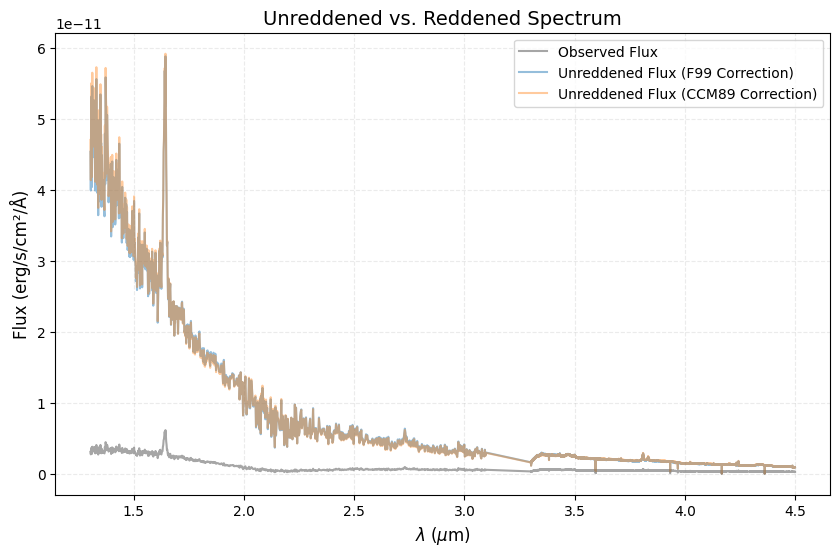

In [ ]:
ext_f99 = F99(Rv=best_Rv_f99)
ext_ccm89 = CCM89(Rv=best_Rv_ccm)

A_lambda = a_v * ext_f99(x_micras_inv)
A_lambda_ccm = a_v * ext_ccm89(x_micras_inv)

F_unred = F_exp_interp * 10 ** (0.4 * A_lambda)
F_unred_ccm = F_exp_interp * 10 ** (0.4 * A_lambda_ccm)

plt.figure(figsize=(10, 6))

plt.plot(
    wl * 1e-7,
    F_exp_interp,
    color="gray",
    alpha=0.7,
    label="Observed Flux",
)

plt.plot(
    wl * 1e-7,
    F_unred,
    color="#1f76b478",
    linewidth=1.5,
    label="Unreddened Flux (F99 Correction)",
)

plt.plot(
    wl * 1e-7,
    F_unred_ccm,
    color="#ff7e0e67",
    linewidth=1.5,
    label="Unreddened Flux (CCM89 Correction)",
)

plt.xlabel(r"$\lambda\; (\mu\text{m})$", fontsize=12)
plt.ylabel(r"Flux (erg/s/cm²/Å)", fontsize=12)
plt.title("Unreddened vs. Reddened Spectrum", fontsize=14)
plt.legend()


plt.savefig(
    fname="Espectro_DesenrojecidoPlanck.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)
plt.grid(alpha=0.25, linestyle="--")
plt.show()